In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# ==========================================
# 1. LOAD AND CLEAN DATA
# ==========================================
# Load the dataset
df = pd.read_csv('food_delivery_data.csv')

# Clean column names and handle missing values
df.columns = df.columns.str.strip()
df.replace('NaN', np.nan, inplace=True)
df.replace('NaN ', np.nan, inplace=True)

# Drop rows where time is missing so we can calculate our time-deltas
df.dropna(subset=['Time_Orderd', 'Time_Order_picked', 'Time_taken(min)'], inplace=True)

# Clean the 'Time_taken(min)' column (remove string characters and convert to float)
df['Time_taken(min)'] = df['Time_taken(min)'].astype(str).str.replace('(min) ', '', regex=False).astype(float)

In [3]:
# ==========================================
# 2. FEATURE ENGINEERING
# ==========================================
print("Engineering time-delta features...")

# Convert time strings to datetime objects
df['Time_Orderd'] = pd.to_datetime('2023-01-01 ' + df['Time_Orderd'].astype(str))
df['Time_Order_picked'] = pd.to_datetime('2023-01-01 ' + df['Time_Order_picked'].astype(str))

# Calculate PREP TIME (Difference between order placed and driver picking it up)
df['prep_duration_mins'] = (df['Time_Order_picked'] - df['Time_Orderd']).dt.total_seconds() / 60
df['prep_duration_mins'] = df['prep_duration_mins'].abs()

# Remove extreme outliers (e.g., data entry errors where prep time is > 120 mins)
df = df[(df['prep_duration_mins'] < 120) & (df['prep_duration_mins'] > 0)]

# Extract hour to find peak times
df['order_hour'] = df['Time_Orderd'].dt.hour

Engineering time-delta features...


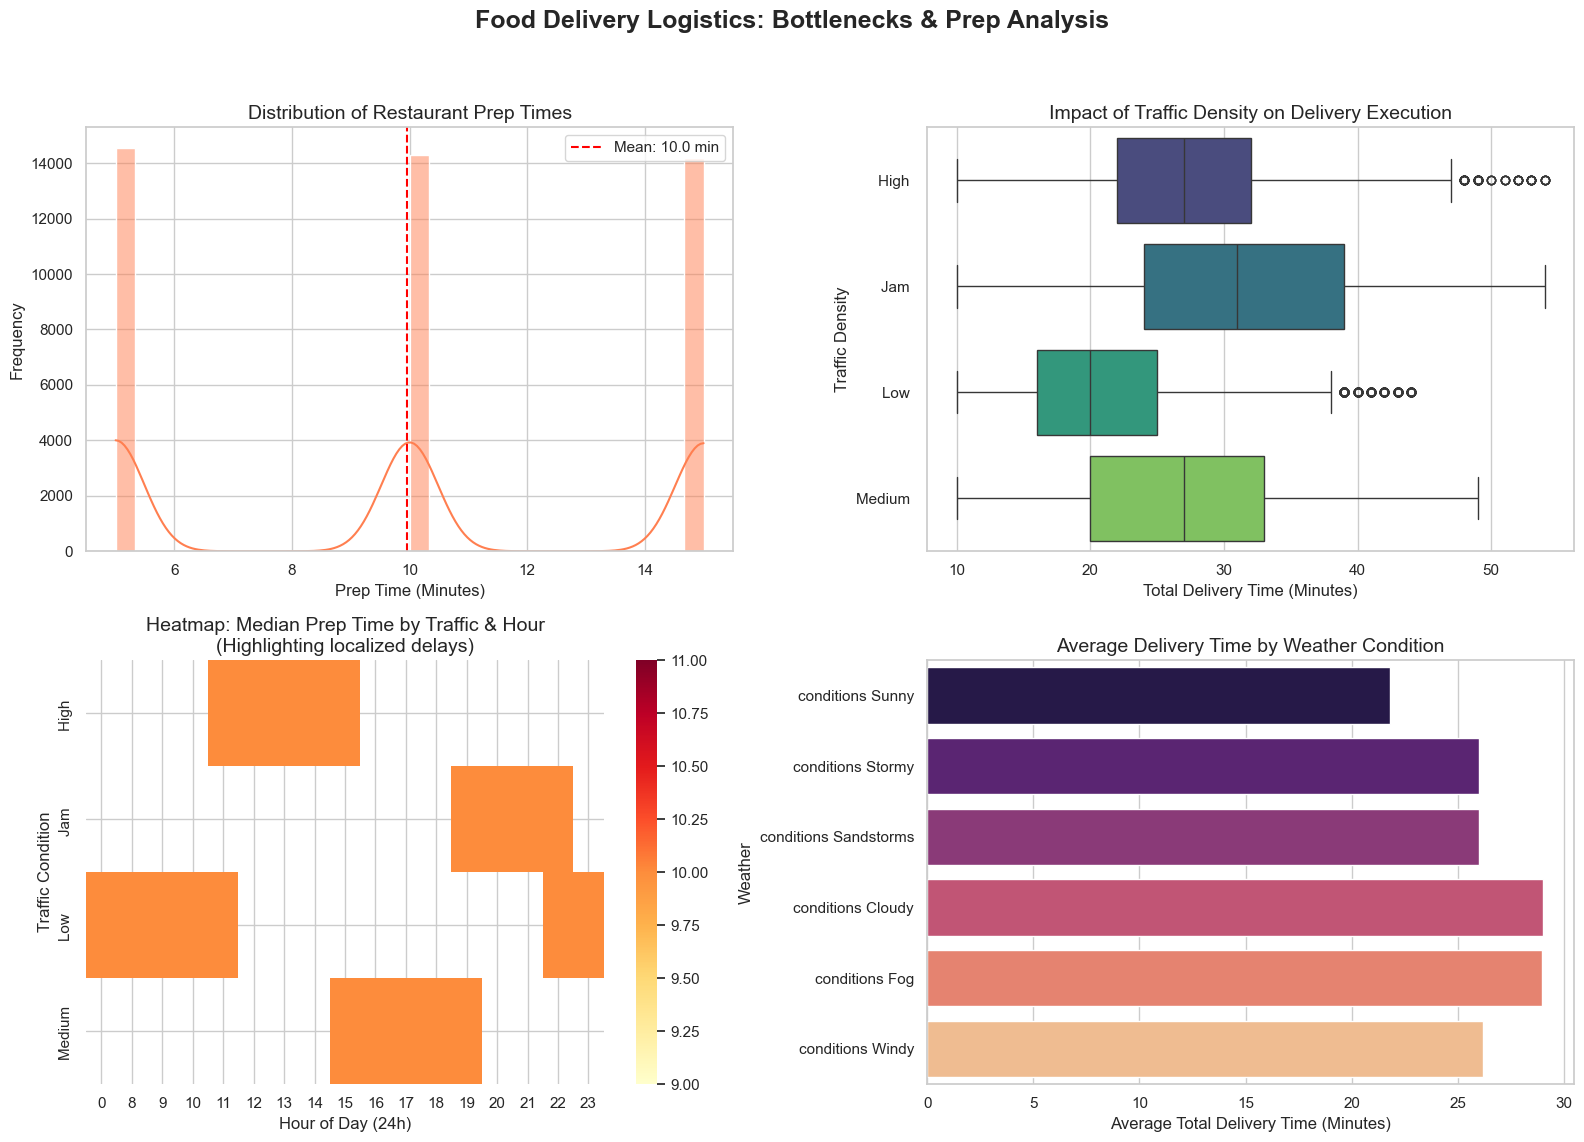

In [4]:
# ==========================================
# 3. EDA & VISUALIZATION
# ==========================================
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('Food Delivery Logistics: Bottlenecks & Prep Analysis', fontsize=18, fontweight='bold')

# --- Chart 1: Distribution of Prep Times ---
sns.histplot(df['prep_duration_mins'], bins=30, kde=True, color='coral', ax=axes[0, 0])
axes[0, 0].set_title('Distribution of Restaurant Prep Times', fontsize=14)
axes[0, 0].set_xlabel('Prep Time (Minutes)')
axes[0, 0].set_ylabel('Frequency')
axes[0, 0].axvline(df['prep_duration_mins'].mean(), color='red', linestyle='--', label=f"Mean: {df['prep_duration_mins'].mean():.1f} min")
axes[0, 0].legend()

# --- Chart 2: Traffic Impact on Total Delivery Time (WARNING FIXED) ---
sns.boxplot(x='Time_taken(min)', y='Road_traffic_density', hue='Road_traffic_density', data=df, palette='viridis', legend=False, ax=axes[0, 1])
axes[0, 1].set_title('Impact of Traffic Density on Delivery Execution', fontsize=14)
axes[0, 1].set_xlabel('Total Delivery Time (Minutes)')
axes[0, 1].set_ylabel('Traffic Density')

# --- Chart 3: Heatmap of Prep Bottlenecks by Hour & Traffic ---
pivot_prep = df.pivot_table(values='prep_duration_mins', index='Road_traffic_density', columns='order_hour', aggfunc='median')
sns.heatmap(pivot_prep, cmap='YlOrRd', annot=False, ax=axes[1, 0])
axes[1, 0].set_title('Heatmap: Median Prep Time by Traffic & Hour\n(Highlighting localized delays)', fontsize=14)
axes[1, 0].set_xlabel('Hour of Day (24h)')
axes[1, 0].set_ylabel('Traffic Condition')

# --- Chart 4: Weather Impact on Delivery Delays (WARNING FIXED) ---
sns.barplot(x='Time_taken(min)', y='Weatherconditions', hue='Weatherconditions', data=df, palette='magma', legend=False, ax=axes[1, 1], errorbar=None)
axes[1, 1].set_title('Average Delivery Time by Weather Condition', fontsize=14)
axes[1, 1].set_xlabel('Average Total Delivery Time (Minutes)')
axes[1, 1].set_ylabel('Weather')

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

In [5]:
print("\n--- Logistics Summary Statistics ---")
print(f"Average Restaurant Prep Time: {df['prep_duration_mins'].mean():.2f} minutes")
print(f"Average Total Delivery Time: {df['Time_taken(min)'].mean():.2f} minutes")


--- Logistics Summary Statistics ---
Average Restaurant Prep Time: 9.96 minutes
Average Total Delivery Time: 26.37 minutes
